### Desafio 11 — Final Integrador

**Fonte principal:** [enunciado](ENUNCIADO_DESAFIO_FINAL.md). O nome do notebook e os títulos A–E foram adaptados à organização solicitada; as atividades, requisitos, perguntas e critérios foram mantidos.

**Entrega final do curso (Aulas 01–10).** Este é um desafio técnico, não um novo projeto de produto. O objetivo é demonstrar decisões conscientes de engenharia utilizando PySpark, Parquet, PostgreSQL/JDBC e Spark UI. **Escreva o pipeline por conta própria:** o pacote `dados_desafio_final.zip` contém somente os dados de entrada, sem a solução do desafio.

#### Cenário

Você recebeu dados de um marketplace fictício e precisa construir um fluxo de ingestão, validação, integração e disponibilização de indicadores. A fonte tem **2 milhões de pedidos**, **20 mil clientes** e **300 produtos**. Existem problemas intencionais de integridade e uma concentração de pedidos em uma única chave de produto para exercitar Data Skew.

##### Preparar os dados no ambiente Docker/Jupyter

A pasta de referência é `datasets/desafio_final_integrador/`, na raiz do repositório. Execute no terminal do container ou em um terminal com Python 3:

```bash
python -m zipfile -e datasets/desafio_final_integrador/dados_desafio_final.zip datasets/desafio_final_integrador
```

O [ZIP dos dados](../../datasets/desafio_final_integrador/dados_desafio_final.zip) acompanha o repositório. A extração disponibiliza `clientes.csv`, `pedidos.csv` e `produtos.csv` em `datasets/desafio_final_integrador/dados/`, com 20 mil clientes, 2 milhões de pedidos e 300 produtos.

Desenvolva este notebook `desafios/desafio_11/desafio_11_final.ipynb` e use um único fluxo organizado com seções Markdown A–E. Não há necessidade de API, dashboard, Airflow ou deploy.

In [3]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
from pyspark.sql.types import StructType, StructField, StringType, DecimalType, IntegerType, DateType, BooleanType
from dotenv import load_dotenv 
import os 

In [4]:
spark = (
    SparkSession.builder
    .appName("desafio_11_final")
    .config("spark.jars", "/opt/jdbc/postgresql.jar")
    .getOrCreate()
)

26/11/01 17:43:14 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


#### Parte A — Ingestão e diagnóstico

1. Leia `pedidos.csv`, `clientes.csv` e `produtos.csv` usando PySpark, **definindo schemas explícitos** para evitar inferência custosa. Considere `data_pedido` uma data, preços/percentuais como tipos decimais adequados e IDs como inteiros/long.
2. Valide contagens, tipos, colunas e alguns registros representativos. Mostre a quantidade de partições da tabela de pedidos.
3. Crie `ano_mes` a partir de `data_pedido`. Use `select`, `filter` e `withColumn` de maneira consciente; inspecione ao menos um `explain(True)` e explique Lazy Evaluation, Catalyst e Column Pruning observados.
4. Registre as contagens de registros por `status` e por `produto_id` (Top 5). Indique qual produto é muito mais frequente.

**Resultado esperado:** 2.000.000 pedidos, 20.000 clientes e 300 produtos, para o conjunto completo. Não faça agregação no DataFrame detalhado antes das auditorias.

**Pergunta A:** quais vantagens o schema explícito traz na leitura de CSV? Em quais transformações ocorreu Shuffle e por quê?

In [5]:
schema_pedidos = StructType([
    StructField("pedido_id", IntegerType(), nullable= True),
    StructField("cliente_id", IntegerType(), nullable= True),
    StructField("produto_id", IntegerType(), nullable= True),
    StructField("data_pedido", DateType(), nullable= True),
    StructField("quantidade", IntegerType(), nullable= True),
    StructField("preco_unitario", DecimalType(10, 2), nullable= True),
    StructField("desconto_pct", DecimalType(), nullable= True),
    StructField("status", StringType(), nullable= True),
    StructField("canal", StringType(), nullable= True)
])

 

In [6]:
schema_clientes = StructType([
    StructField("cliente_id", IntegerType(), nullable= True),
    StructField("cidade", StringType(), nullable= True),
    StructField("uf", StringType(), nullable= True),
    StructField("segmento", StringType(), nullable= True),
    StructField("ativo", BooleanType(), nullable= True)
])


In [7]:
schema_produtos = StructType([
    StructField("produto_id", IntegerType(), nullable= True),
    StructField("descricao", StringType(), nullable= True),
    StructField("categoria", StringType(), nullable= True),
    StructField("preco_referencia", DecimalType(10, 2), nullable= True),
    StructField("ativo", BooleanType(), nullable= True)
])



In [8]:
df_pedidos = spark.read.csv("/workspace/datasets/desafio_final_integrador/dados/pedidos.csv", header= True, schema= schema_pedidos)
df_clientes = spark.read.csv("/workspace/datasets/desafio_final_integrador/dados/clientes.csv", header= True, schema= schema_clientes)
df_produtos = spark.read.csv("/workspace/datasets/desafio_final_integrador/dados/produtos.csv", header= True, schema= schema_produtos)

In [9]:
df_produtos.count()

300

In [10]:
df_produtos.printSchema()

root
 |-- produto_id: integer (nullable = true)
 |-- descricao: string (nullable = true)
 |-- categoria: string (nullable = true)
 |-- preco_referencia: decimal(10,2) (nullable = true)
 |-- ativo: boolean (nullable = true)



In [11]:
df_produtos.columns

['produto_id', 'descricao', 'categoria', 'preco_referencia', 'ativo']

In [12]:
df_produtos.show(5)

+----------+-----------+----------+----------------+-----+
|produto_id|  descricao| categoria|preco_referencia|ativo|
+----------+-----------+----------+----------------+-----+
|         1|Produto 001| alimentos|           10.37| true|
|         2|Produto 002|   bebidas|           10.74| true|
|         3|Produto 003|   higiene|           11.11| true|
|         4|Produto 004|   limpeza|           11.48| true|
|         5|Produto 005|utilidades|           11.85| true|
+----------+-----------+----------+----------------+-----+
only showing top 5 rows



In [13]:
df_clientes.count()

20000

In [14]:
df_clientes.count()

20000

In [15]:
df_clientes.printSchema()

root
 |-- cliente_id: integer (nullable = true)
 |-- cidade: string (nullable = true)
 |-- uf: string (nullable = true)
 |-- segmento: string (nullable = true)
 |-- ativo: boolean (nullable = true)



In [16]:
df_clientes.columns

['cliente_id', 'cidade', 'uf', 'segmento', 'ativo']

In [17]:
df_clientes.show(5)

+----------+--------------+---+-----------+-----+
|cliente_id|        cidade| uf|   segmento|ativo|
+----------+--------------+---+-----------+-----+
|         1|      Salvador| BA|corporativo| true|
|         2|     São Paulo| SP|    atacado| true|
|         3|Rio de Janeiro| RJ|     varejo| true|
|         4|Belo Horizonte| MG|corporativo| true|
|         5|        Recife| PE|    atacado| true|
+----------+--------------+---+-----------+-----+
only showing top 5 rows



In [18]:
df_pedidos.count()

2000000

In [19]:
df_pedidos.printSchema()

root
 |-- pedido_id: integer (nullable = true)
 |-- cliente_id: integer (nullable = true)
 |-- produto_id: integer (nullable = true)
 |-- data_pedido: date (nullable = true)
 |-- quantidade: integer (nullable = true)
 |-- preco_unitario: decimal(10,2) (nullable = true)
 |-- desconto_pct: decimal(10,0) (nullable = true)
 |-- status: string (nullable = true)
 |-- canal: string (nullable = true)



In [20]:
df_pedidos.columns

['pedido_id',
 'cliente_id',
 'produto_id',
 'data_pedido',
 'quantidade',
 'preco_unitario',
 'desconto_pct',
 'status',
 'canal']

In [21]:
df_pedidos.show(5)

+---------+----------+----------+-----------+----------+--------------+------------+---------+-----------+
|pedido_id|cliente_id|produto_id|data_pedido|quantidade|preco_unitario|desconto_pct|   status|      canal|
+---------+----------+----------+-----------+----------+--------------+------------+---------+-----------+
|        1|        38|         1| 2025-01-01|         2|         10.11|           5| pendente|       loja|
|        2|        75|         1| 2025-01-02|         3|         10.22|          10|cancelado|marketplace|
|        3|       112|         1| 2025-01-03|         4|         10.33|           0| entregue|  ecommerce|
|        4|       149|         1| 2025-01-04|         5|         10.44|           5|concluido|       loja|
|        5|       186|         1| 2025-01-05|         1|         10.55|          10| pendente|marketplace|
+---------+----------+----------+-----------+----------+--------------+------------+---------+-----------+
only showing top 5 rows



In [22]:
df_pedidos.rdd.getNumPartitions()

12

In [23]:
df_pedidos_coluna_ano_mes = (
    df_pedidos.withColumn("ano_mes", F.date_format(F.col("data_pedido"), "yyyy-MM"))
)

In [24]:
df_pedidos_por_status = (
    df_pedidos.groupBy("status")
    .agg(F.count("*").alias("quantidade_por_status"))
)

In [25]:
df_produtos_frequentes = (
    df_pedidos.groupBy("produto_id")
    .agg(F.count("pedido_id").alias("quantidade_pedidos"))
    .orderBy(F.col("quantidade_pedidos").desc())
    .limit(5)
)

In [26]:
df_produtos_frequentes.show()

+----------+------------------+
|produto_id|quantidade_pedidos|
+----------+------------------+
|         1|           1380000|
|       119|             26088|
|       210|             26087|
|        28|             26087|
|       236|             26087|
+----------+------------------+



In [27]:
df_produtos_frequentes.explain(True)

== Parsed Logical Plan ==
GlobalLimit 5
+- LocalLimit 5
   +- Sort [quantidade_pedidos#226L DESC NULLS LAST], true
      +- Aggregate [produto_id#2], [produto_id#2, count(pedido_id#0) AS quantidade_pedidos#226L]
         +- Relation [pedido_id#0,cliente_id#1,produto_id#2,data_pedido#3,quantidade#4,preco_unitario#5,desconto_pct#6,status#7,canal#8] csv

== Analyzed Logical Plan ==
produto_id: int, quantidade_pedidos: bigint
GlobalLimit 5
+- LocalLimit 5
   +- Sort [quantidade_pedidos#226L DESC NULLS LAST], true
      +- Aggregate [produto_id#2], [produto_id#2, count(pedido_id#0) AS quantidade_pedidos#226L]
         +- Relation [pedido_id#0,cliente_id#1,produto_id#2,data_pedido#3,quantidade#4,preco_unitario#5,desconto_pct#6,status#7,canal#8] csv

== Optimized Logical Plan ==
GlobalLimit 5
+- LocalLimit 5
   +- Sort [quantidade_pedidos#226L DESC NULLS LAST], true
      +- Aggregate [produto_id#2], [produto_id#2, count(pedido_id#0) AS quantidade_pedidos#226L]
         +- Project [pedido_id#

Pergunta A: quais vantagens um schema explícito oferece na leitura de arquivos CSV? Quais das operações realizadas exigiram Shuffle e por quê?

Resposta: Com a utilização do schema explicito passando a tipagem de cada coluna manualmente o spark consegue definir a tipagem dos dados do csv com maior facilidade, economizando processamento, cada dado terá exatamente o tipo definido. Das operações realizadas df_pedidos_por_status e df_produtos_frequentes como utilizaram groupBy, acabou que foi exigido um shuffle, na grande maioria dos casos funções de agregação acabam redistribuindo dados entre partições, cada partição fará uma agregação individual e por fim ocorrera o hashagregate final, onde os dados se juntaram para entregar o resultado final  

#### Parte B — Qualidade, joins e agregações

1. Investigue **pedidos sem cliente correspondente** e **pedidos sem produto correspondente**, utilizando `left_anti` ou abordagem equivalente, sem perder os registros rejeitados da auditoria.
2. Investigue `quantidade <= 0` e documente uma regra de tratamento. **Não descarte silenciosamente** os registros inválidos.
3. Construa um DataFrame de pedidos válidos contendo também `uf`, `categoria` e `descricao` a partir das dimensões. Evite duplicação indevida de linhas; confira unicidade das chaves nas dimensões.
4. Gere indicadores de pedidos **concluídos** por `ano_mes`, `uf` e `categoria`: número de pedidos, total de unidades e receita líquida após desconto (defina e documente a fórmula). Use funções de agregação do Spark.
5. Examine o plano físico de ao menos um join e uma agregação. Identifique `HashAggregate partial`, `Exchange` e `HashAggregate final`, quando presentes.

**Auditoria orientativa para 2 milhões:** 40.000 pedidos possuem IDs de cliente fora da dimensão; 20.000 possuem IDs de produto fora da dimensão; alguns pedidos possuem quantidade zero. Há sobreposição entre os grupos de erros. Não some as contagens de erros para obter linhas rejeitadas únicas sem considerar a interseção.

**Pergunta B:** por que um join com dimensão não única pode inflar métricas? Qual a diferença entre `left_anti`, `left_semi` e `inner` no contexto dessa auditoria?

In [28]:
df_pedidos_sem_clientes = df_pedidos.join(
    df_clientes,
    df_clientes.cliente_id == df_pedidos.cliente_id,
    "left_anti"
)

In [29]:
df_pedidos_sem_clientes.show(5)

+---------+----------+----------+-----------+----------+--------------+------------+---------+-----------+
|pedido_id|cliente_id|produto_id|data_pedido|quantidade|preco_unitario|desconto_pct|   status|      canal|
+---------+----------+----------+-----------+----------+--------------+------------+---------+-----------+
|       50|     20017|         1| 2025-02-19|         1|         15.50|          10|cancelado|marketplace|
|      100|     20016|       303| 2025-04-10|         1|         21.00|           5|concluido|       loja|
|      150|     20015|         1| 2025-05-30|         1|         26.50|           0|cancelado|  ecommerce|
|      200|     20014|       305| 2025-01-20|         1|         32.00|          10|concluido|marketplace|
|      250|     20013|         1| 2025-03-11|         1|         37.50|           5|cancelado|       loja|
+---------+----------+----------+-----------+----------+--------------+------------+---------+-----------+
only showing top 5 rows



In [30]:
df_pedidos_sem_produtos = df_pedidos.join(
    df_produtos,
    df_produtos.produto_id == df_pedidos.produto_id,
    "left_anti"
)

In [31]:
df_pedidos_sem_produtos.show(5)

+---------+----------+----------+-----------+----------+--------------+------------+---------+-----------+
|pedido_id|cliente_id|produto_id|data_pedido|quantidade|preco_unitario|desconto_pct|   status|      canal|
+---------+----------+----------+-----------+----------+--------------+------------+---------+-----------+
|      100|     20016|       303| 2025-04-10|         1|         21.00|           5|concluido|       loja|
|      200|     20014|       305| 2025-01-20|         1|         32.00|          10|concluido|marketplace|
|      300|     20012|       307| 2025-04-30|         1|         43.00|           0|concluido|  ecommerce|
|      400|     20010|       302| 2025-02-09|         1|         54.00|           5|concluido|       loja|
|      500|     20008|       304| 2025-05-20|         1|         65.00|          10|concluido|marketplace|
+---------+----------+----------+-----------+----------+--------------+------------+---------+-----------+
only showing top 5 rows



In [32]:
df_quantidade_menor_zero = (
    df_pedidos.select("quantidade")
    .filter(F.col("quantidade") <= 0)
)

In [33]:
df_quantidade_menor_zero.count()

20618

In [34]:
df_pedidos_quantidade_tratamento = (
    df_pedidos_coluna_ano_mes.withColumn(
        "pedido_invalido",
        F.when(F.col("quantidade") <= 0, "invalidos").otherwise("pedido_valido")
    )
)

Regra de qualidade da coluna quantidade: pedidos com quantidade menor ou igual a zero, ou nula, serão classificados como inválidos e não participarão da construção dos indicadores analíticos. Os registros permanecerão disponíveis na fonte bruta para auditoria e rastreabilidade. Foram indetificados 20618 produtos com quantidades invalidas

In [35]:
(
    df_clientes.groupBy(F.col("cliente_id"))
    .agg(F.count("*").alias("quantidade_clientes"))
    .filter(F.col("quantidade_clientes") > 1)
).show()

+----------+-------------------+
|cliente_id|quantidade_clientes|
+----------+-------------------+
+----------+-------------------+



In [36]:
(
    df_produtos.groupBy(F.col("produto_id"))
    .agg(F.count("*").alias("quantidade_produtos"))
    .filter(F.col("quantidade_produtos") > 1)
).show()

+----------+-------------------+
|produto_id|quantidade_produtos|
+----------+-------------------+
+----------+-------------------+



In [37]:
df_pedidos_curados = (
    df_pedidos_coluna_ano_mes.filter(F.col("quantidade") > 0)
)

In [38]:
df_final_parteb = (
    df_pedidos_curados.join(df_clientes, "cliente_id", "inner")
    .join(df_produtos, "produto_id", "inner")
    .select(
        "produto_id", 
        "cliente_id", 
        "pedido_id", 
        "data_pedido", 
        "quantidade" ,
        "preco_unitario",
        "desconto_pct", 
        "status", 
        "canal",
        "ano_mes", 
        "cidade", 
        "uf", 
        "segmento", 
        "descricao", 
        "categoria", 
        "preco_referencia", 
        df_clientes["ativo"]
    )
) 

In [39]:
df_final_parteb.show()

+----------+----------+---------+-----------+----------+--------------+------------+---------+-----------+-------+--------------+---+-----------+-----------+---------+----------------+-----+
|produto_id|cliente_id|pedido_id|data_pedido|quantidade|preco_unitario|desconto_pct|   status|      canal|ano_mes|        cidade| uf|   segmento|  descricao|categoria|preco_referencia|ativo|
+----------+----------+---------+-----------+----------+--------------+------------+---------+-----------+-------+--------------+---+-----------+-----------+---------+----------------+-----+
|         1|        38|        1| 2025-01-01|         2|         10.11|           5| pendente|       loja|2025-01|Rio de Janeiro| RJ|    atacado|Produto 001|alimentos|           10.37| true|
|         1|        75|        2| 2025-01-02|         3|         10.22|          10|cancelado|marketplace|2025-01|        Recife| PE|     varejo|Produto 001|alimentos|           10.37| true|
|         1|       112|        3| 2025-01-03|

In [40]:
df_pedidos_curados.count()

1979382

In [41]:
df_final_parteb.count()

1939794

In [42]:
df_indicadores_vendas = (
    df_final_parteb.filter(F.col("status") == "concluido")
    .groupBy("ano_mes", "uf" , "categoria")
    .agg(
        F.count("status").alias("quantidade_pedidos_concluidos"),
        F.sum("quantidade").alias("total_unidades_vendidas"),
        F.round(F.sum(F.col("quantidade") * F.col("preco_unitario") * (1 - F.col("desconto_pct") / 100)), 2).alias("receita_liquida_total")
    )
    
)

In [43]:
df_indicadores_vendas.printSchema()

root
 |-- ano_mes: string (nullable = true)
 |-- uf: string (nullable = true)
 |-- categoria: string (nullable = true)
 |-- quantidade_pedidos_concluidos: long (nullable = false)
 |-- total_unidades_vendidas: long (nullable = true)
 |-- receita_liquida_total: decimal(34,2) (nullable = true)



In [44]:
df_indicadores_vendas.explain(True)

== Parsed Logical Plan ==
'Aggregate ['ano_mes, 'uf, 'categoria], ['ano_mes, 'uf, 'categoria, count('status) AS quantidade_pedidos_concluidos#632, sum('quantidade) AS total_unidades_vendidas#634, round(sum((('quantidade * 'preco_unitario) * (1 - ('desconto_pct / 100)))), 2) AS receita_liquida_total#636]
+- Filter (status#7 = concluido)
   +- Project [produto_id#2, cliente_id#1, pedido_id#0, data_pedido#3, quantidade#4, preco_unitario#5, desconto_pct#6, status#7, canal#8, ano_mes#192, cidade#19, uf#20, segmento#21, descricao#29, categoria#30, preco_referencia#31, ativo#22]
      +- Project [produto_id#2, cliente_id#1, pedido_id#0, data_pedido#3, quantidade#4, preco_unitario#5, desconto_pct#6, status#7, canal#8, ano_mes#192, cidade#19, uf#20, segmento#21, ativo#22, descricao#29, categoria#30, preco_referencia#31, ativo#32]
         +- Join Inner, (produto_id#2 = produto_id#28)
            :- Project [cliente_id#1, pedido_id#0, produto_id#2, data_pedido#3, quantidade#4, preco_unitario#5, 

Pergunta B: como a cardinalidade de um join pode comprometer os indicadores? Quando left_anti é mais apropriado que inner? Qual é o papel do left_semi nessa análise?

Resposta: A cardianalidade incorreta pode duplicar ou omitir registros acidentalmente,distorcendo agregações (como somas e médias) e levando a tomadas de decisão baseadas em dados inflados ou incompletos. Utiliza-se left_anti quando queremos indentificar registros que não possuem dados na tabela da direita, então vamos supor um cenario onde temos uma tabela de clientes e pedidos, usando left_anti é possivel encontrar clientes sem pedido. Ja left_semi ja tem o papel inverso, com ele é possivel identificar pedidos sem clientes 

#### Parte C — Armazenamento em Parquet

1. Salve uma versão **curada** dos pedidos válidos em Parquet, particionando fisicamente por `ano_mes` (seis meses no dataset de referência). Evite particionar fisicamente por `pedido_id` ou `cliente_id`.
2. Leia o diretório raiz do Parquet salvo. Faça um filtro para um mês específico e selecione somente algumas colunas. Use `explain(True)` para procurar `PartitionFilters`, `ReadSchema` e `PushedFilters` quando aplicáveis.
3. Compare conceitualmente CSV vs. Parquet, Spark Partitions vs. pastas `partitionBy()`, e Shuffle vs. Partition Pruning.
4. Registre quantidade de arquivos e a escolha de quantidade de partições de escrita; explique o trade-off com small files.

**Pergunta C:** por que `partitionBy("ano_mes")` pode ser útil neste conjunto, mas `partitionBy("cliente_id")` provavelmente não é?

In [45]:
df_final_parteb.write.mode("overwrite").partitionBy("ano_mes").parquet("/workspace/desafios/desafio_11/arquivos_parquet")

26/11/01 17:44:52 WARN MemoryManager: Total allocation exceeds 95.00% (1,020,054,720 bytes) of heap memory
Scaling row group sizes to 95.00% for 8 writers
26/11/01 17:44:52 WARN MemoryManager: Total allocation exceeds 95.00% (1,020,054,720 bytes) of heap memory
Scaling row group sizes to 84.44% for 9 writers
26/11/01 17:44:52 WARN MemoryManager: Total allocation exceeds 95.00% (1,020,054,720 bytes) of heap memory
Scaling row group sizes to 76.00% for 10 writers
26/11/01 17:44:52 WARN MemoryManager: Total allocation exceeds 95.00% (1,020,054,720 bytes) of heap memory
Scaling row group sizes to 69.09% for 11 writers
26/11/01 17:44:52 WARN MemoryManager: Total allocation exceeds 95.00% (1,020,054,720 bytes) of heap memory
Scaling row group sizes to 63.33% for 12 writers
26/11/01 17:44:55 WARN MemoryManager: Total allocation exceeds 95.00% (1,020,054,720 bytes) of heap memory
Scaling row group sizes to 69.09% for 11 writers
26/11/01 17:44:55 WARN MemoryManager: Total allocation exceeds 95.

In [46]:
df_parquet_anomes = spark.read.parquet("/workspace/desafios/desafio_11/arquivos_parquet")

In [47]:
df_parquet_filtrado = (
    df_parquet_anomes.select(
        "produto_id",
        "cliente_id",
        "pedido_id",
        "quantidade",
        "desconto_pct"
    )
    .filter(F.col("ano_mes") == "2025-06")
    
)

In [48]:
df_parquet_filtrado.explain(True)

== Parsed Logical Plan ==
'Filter ('ano_mes = 2025-06)
+- Project [produto_id#687, cliente_id#688, pedido_id#689, quantidade#691, desconto_pct#693]
   +- Relation [produto_id#687,cliente_id#688,pedido_id#689,data_pedido#690,quantidade#691,preco_unitario#692,desconto_pct#693,status#694,canal#695,cidade#696,uf#697,segmento#698,descricao#699,categoria#700,preco_referencia#701,ativo#702,ano_mes#703] parquet

== Analyzed Logical Plan ==
produto_id: int, cliente_id: int, pedido_id: int, quantidade: int, desconto_pct: decimal(10,0)
Project [produto_id#687, cliente_id#688, pedido_id#689, quantidade#691, desconto_pct#693]
+- Filter (ano_mes#703 = 2025-06)
   +- Project [produto_id#687, cliente_id#688, pedido_id#689, quantidade#691, desconto_pct#693, ano_mes#703]
      +- Relation [produto_id#687,cliente_id#688,pedido_id#689,data_pedido#690,quantidade#691,preco_unitario#692,desconto_pct#693,status#694,canal#695,cidade#696,uf#697,segmento#698,descricao#699,categoria#700,preco_referencia#701,ativo

Pergunta C: por que particionar fisicamente por mês pode fazer sentido nesse dataset, enquanto particionar pelo identificador de cliente pode trazer problemas?

Resposta: Nesse cenario faz mas sentido sentido particionar por mes, pois, a partir dessas colunas, é possivel trazer metricas de uma melhor forma, e não gerará small files, ja que esse dataset em especifico so possui 6 meses resultando em uma baixa cardinalidade. Particionar por cliente_id não seria muito iteligente, essa escolha muito provavelmente vai gerar small files, consumindo muito processamento causando um overhead gigantesco para o spark gerenciar as tasks.

#### Parte D — PostgreSQL e JDBC

1. Escreva a tabela agregada de indicadores (não os 2 milhões de pedidos) no PostgreSQL local como `public.desafio_final_indicadores`, via JDBC. Utilize `batchsize` se desejar e documente o modo de escrita escolhido.
2. Consulte no PostgreSQL o `COUNT(*)`, colunas/tipos e uma amostra. Leia a tabela novamente pelo Spark via JDBC, validando quantidades e tipos.
3. Explique quando usar `append` e `overwrite`, seus riscos (duplicação e recriação de tabela) e por que `numPartitions`, `lowerBound`, `upperBound` e `fetchsize` não são sinônimos.
4. Justifique por que **não há necessidade de leitura JDBC paralela** para uma tabela agregada pequena. Relacione isso ao exercício anterior com 2 milhões de linhas no PostgreSQL.

**Pergunta D:** como validaria a integridade dos dados entre a tabela agregada no Spark e a tabela persistida no PostgreSQL?

In [49]:
load_dotenv()

True

In [50]:
url_jdbc = "jdbc:postgresql://postgres:5432/spark_db"

credencias = {
    "user" : "postgres",
    "password" : os.getenv("POSTGRES_PASSWORD"),
    "driver" : "org.postgresql.Driver"
}

In [51]:
df_indicadores_vendas.write.jdbc(
    url= url_jdbc,
    table= "public.desafio_final_indicadores",
    mode= "overwrite",
    properties= credencias
)

54 Registros identificados 


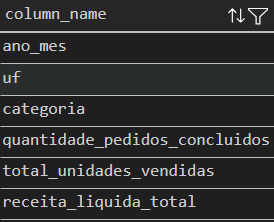

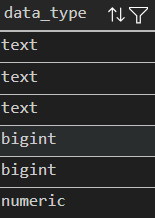

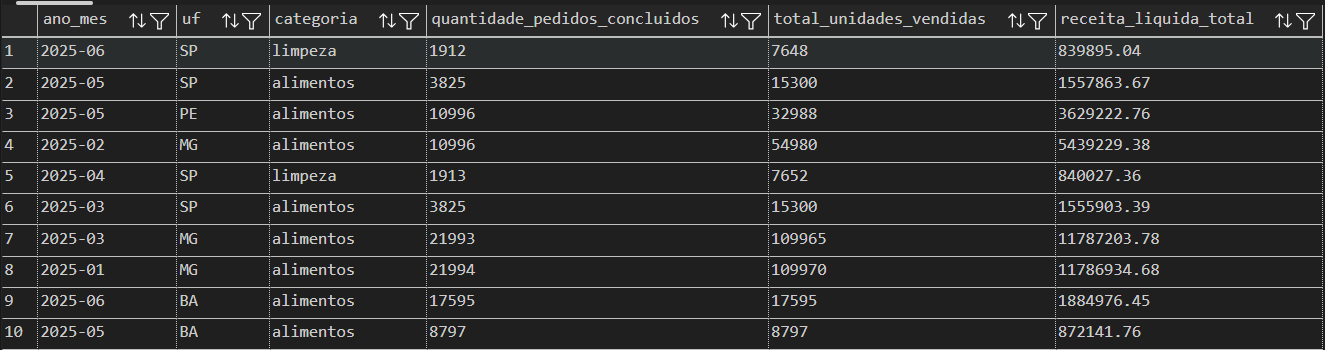

In [52]:
df_indicadores_postgres = spark.read.jdbc(
    url= url_jdbc,
    properties= credencias,
    table= "public.desafio_final_indicadores",
    
)

In [53]:
df_indicadores_postgres.printSchema()

root
 |-- ano_mes: string (nullable = true)
 |-- uf: string (nullable = true)
 |-- categoria: string (nullable = true)
 |-- quantidade_pedidos_concluidos: long (nullable = true)
 |-- total_unidades_vendidas: long (nullable = true)
 |-- receita_liquida_total: decimal(34,2) (nullable = true)



In [54]:
df_indicadores_postgres.count()

54

In [55]:
df_indicadores_postgres.show(10)

+-------+---+---------+-----------------------------+-----------------------+---------------------+
|ano_mes| uf|categoria|quantidade_pedidos_concluidos|total_unidades_vendidas|receita_liquida_total|
+-------+---+---------+-----------------------------+-----------------------+---------------------+
|2025-06| SP|  limpeza|                         1912|                   7648|            839895.04|
|2025-05| SP|alimentos|                         3825|                  15300|           1557863.67|
|2025-05| PE|alimentos|                        10996|                  32988|           3629222.76|
|2025-02| MG|alimentos|                        10996|                  54980|           5439229.38|
|2025-04| SP|  limpeza|                         1913|                   7652|            840027.36|
|2025-03| SP|alimentos|                         3825|                  15300|           1555903.39|
|2025-03| MG|alimentos|                        21993|                 109965|          11787203.78|


In [56]:
df_indicadores_vendas.count()

54

In [57]:
df_indicadores_postgres.count()

54

In [58]:
df_comparacao_spark = (
    df_indicadores_vendas.groupBy("quantidade_pedidos_concluidos", "total_unidades_vendidas", "receita_liquida_total")
    .agg(
        F.sum("quantidade_pedidos_concluidos").alias("quantidade_total_pedidos_concluidos"),
        F.sum("total_unidades_vendidas").alias("soma_unidades_vendidas"),
        F.sum("receita_liquida_total").alias("soma_receita_liquida_total")
    )
).show(5)


+-----------------------------+-----------------------+---------------------+-----------------------------------+----------------------+--------------------------+
|quantidade_pedidos_concluidos|total_unidades_vendidas|receita_liquida_total|quantidade_total_pedidos_concluidos|soma_unidades_vendidas|soma_receita_liquida_total|
+-----------------------------+-----------------------+---------------------+-----------------------------------+----------------------+--------------------------+
|                         1913|                   7652|            841649.76|                               1913|                  7652|                 841649.76|
|                        17594|                  17594|           1886445.60|                              17594|                 17594|                1886445.60|
|                         3825|                  15300|           1556848.85|                               3825|                 15300|                1556848.85|
|               

In [59]:
df_comparacao_postgres = (
    df_indicadores_postgres.groupBy("quantidade_pedidos_concluidos", "total_unidades_vendidas", "receita_liquida_total")
    .agg(
        F.sum("quantidade_pedidos_concluidos").alias("quantidade_total_pedidos_concluidos"),
        F.sum("total_unidades_vendidas").alias("soma_unidades_vendidas"),
        F.sum("receita_liquida_total").alias("soma_receita_liquida_total")
    )
).show(5)

+-----------------------------+-----------------------+---------------------+-----------------------------------+----------------------+--------------------------+
|quantidade_pedidos_concluidos|total_unidades_vendidas|receita_liquida_total|quantidade_total_pedidos_concluidos|soma_unidades_vendidas|soma_receita_liquida_total|
+-----------------------------+-----------------------+---------------------+-----------------------------------+----------------------+--------------------------+
|                         1913|                   7652|            841649.76|                               1913|                  7652|                 841649.76|
|                        17594|                  17594|           1886445.60|                              17594|                 17594|                1886445.60|
|                         3825|                  15300|           1556848.85|                               3825|                 15300|                1556848.85|
|               

In [60]:
df_comparacao_left_anti = df_indicadores_postgres.join(
    df_indicadores_vendas,
    on= ["ano_mes", "uf", "categoria"],
    how= "left_anti"
)

In [61]:
df_comparacao_left_anti.count()

0

In [62]:
df_comparacao2_left_anti = df_indicadores_vendas.join(
    df_indicadores_postgres,
    on= ["ano_mes", "uf", "categoria"],
    how= "left_anti"
)

In [63]:
df_comparacao2_left_anti.count()

0

In [64]:
df_comparacao_inner = df_indicadores_postgres.alias("pg").join(
    df_indicadores_vendas.alias("spk"),
    on= ["ano_mes", "uf", "categoria"],
    how= "inner"
)

In [65]:
df_comparacao_inner.show(1)

+-------+---+---------+-----------------------------+-----------------------+---------------------+-----------------------------+-----------------------+---------------------+
|ano_mes| uf|categoria|quantidade_pedidos_concluidos|total_unidades_vendidas|receita_liquida_total|quantidade_pedidos_concluidos|total_unidades_vendidas|receita_liquida_total|
+-------+---+---------+-----------------------------+-----------------------+---------------------+-----------------------------+-----------------------+---------------------+
|2025-06| SP|  limpeza|                         1912|                   7648|            839895.04|                         1912|                   7648|            839895.04|
+-------+---+---------+-----------------------------+-----------------------+---------------------+-----------------------------+-----------------------+---------------------+
only showing top 1 row



In [66]:
(
    df_comparacao_inner.select(
        "ano_mes",
        "uf",
        "categoria",
        F.col("pg.quantidade_pedidos_concluidos").alias("pedidos_concluidos_postgres"),
        F.col("pg.total_unidades_vendidas").alias("total_unidades_vendidas_postgres"),
        F.col("pg.receita_liquida_total").alias("receita_liquida_total_postgres"),
        F.col("spk.quantidade_pedidos_concluidos").alias("pedidos_concluidos_spark"),
        F.col("spk.total_unidades_vendidas").alias("total_unidades_vendidas_spark"),
        F.col("spk.receita_liquida_total").alias("receita_liquida_total_spark"),
    )
).show()

+-------+---+----------+---------------------------+--------------------------------+------------------------------+------------------------+-----------------------------+---------------------------+
|ano_mes| uf| categoria|pedidos_concluidos_postgres|total_unidades_vendidas_postgres|receita_liquida_total_postgres|pedidos_concluidos_spark|total_unidades_vendidas_spark|receita_liquida_total_spark|
+-------+---+----------+---------------------------+--------------------------------+------------------------------+------------------------+-----------------------------+---------------------------+
|2025-06| SP|   limpeza|                       1912|                            7648|                     839895.04|                    1912|                         7648|                  839895.04|
|2025-05| SP| alimentos|                       3825|                           15300|                    1557863.67|                    3825|                        15300|                 1557863.67|


In [67]:
df_divergencias = df_comparacao_inner.filter(
    (F.col("pg.quantidade_pedidos_concluidos") != F.col("spk.quantidade_pedidos_concluidos")) |
    (F.col("pg.total_unidades_vendidas") != F.col("spk.total_unidades_vendidas")) |
    (F.col("pg.receita_liquida_total") != F.col("spk.receita_liquida_total"))
)

In [68]:
df_divergencias.show()

+-------+---+---------+-----------------------------+-----------------------+---------------------+-----------------------------+-----------------------+---------------------+
|ano_mes| uf|categoria|quantidade_pedidos_concluidos|total_unidades_vendidas|receita_liquida_total|quantidade_pedidos_concluidos|total_unidades_vendidas|receita_liquida_total|
+-------+---+---------+-----------------------------+-----------------------+---------------------+-----------------------------+-----------------------+---------------------+
+-------+---+---------+-----------------------------+-----------------------+---------------------+-----------------------------+-----------------------+---------------------+



In [69]:
df_unicidade_chaves_postgres = (
    df_indicadores_vendas.groupBy("ano_mes", "uf", "categoria")
    .agg(F.count("*").alias("quantidade_linhas"))
    .filter(F.col("quantidade_linhas") > 1)
).show()

+-------+---+---------+-----------------+
|ano_mes| uf|categoria|quantidade_linhas|
+-------+---+---------+-----------------+
+-------+---+---------+-----------------+



Explique os riscos de append e overwrite, e o papel de configurações como numPartitions, fetchsize, batchsize, lowerBound e upperBound.

Resposta: O append acrecemta regostrps a tabela existente, se o carga for executada novamente, poderá ocorrer a duplicação de dados.
Já no overwrite ocorre a substituiçã dos dados podendo recriar a tabela, trazendo riscos de perda de dados, inidices e outras definições da tabela.

Sobre os outros metodos de paralalelismo utilizando o numPartition, fetchsize para realizar a leitura dos dados a partir de um lote definido, batchsize, para fazer a persistencias dos dados tambem a partir de uma definição de um lote, lowerBound valo minimo de leitura e upperbound, valor maximo da leitura. Nesse cenario em especificio não se fez necessario a utilização desses metodos, pois so foram persistidos apenas 54 registros no banco de dados.

Pergunta D: como você garantiria que os dados persistidos no PostgreSQL correspondem exatamente aos indicadores produzidos pelo Spark?

Resposta: Após a persistencias dos dados no banco, eu iria fazer uma comparação com o que foi escrito e o que o spark produziu, iria ler o dados escritos do banco, e iria utilizar as mesmas metricas que foram utilizadas na construção dos indicadores no spark, para verificar se existe coerencia com os dados que foram escritos no banco.

#### Parte E — Performance e diagnóstico

1. Compare `repartition(8)` com `repartition(8, "produto_id")` no DataFrame detalhado de pedidos. Meça a quantidade de registros por partição com `spark_partition_id()`. Explique o desequilíbrio produzido pela chave frequente.
2. Compare planos de `BroadcastHashJoin` e `SortMergeJoin` usando a tabela de produtos. Para testes de desempenho do join, utilize **a mesma amostra de até 200 mil pedidos nos dois lados da comparação**, para preservar tempo/memória no ambiente local. Solicite o SMJ com `hint("merge")`, e documente as configurações temporárias necessárias; restaure-as ao final. Garanta que a descrição/categoria da dimensão seja utilizada no resultado analítico, impedindo que o otimizador elimine um join desnecessário.
3. Confirme se o AQE está ativado e encontre `AdaptiveSparkPlan`; explique uma otimização que o AQE pode aplicar e sua limitação.
4. Escolha um DataFrame intermediário reutilizado em pelo menos duas consultas; compare execução sem persistência vs. com `cache()`, identifique `InMemoryTableScan` e finalize com `unpersist()`. Não alegue ganho de performance sem evidência.
5. No Spark UI, registre para ao menos uma consulta de join/agregação: Jobs/Stages, duração de Tasks, Shuffle Read/Write e spill (quando houver). Se faltar medição, documente a limitação em vez de inventar números.

**Pergunta E:** com base em seu Physical Plan e Spark UI, qual gargalo foi comprovado? O que é apenas hipótese? Cite duas decisões que você manteria ou alteraria em um pipeline real.

In [70]:
df_repartition = df_final_parteb.repartition(8)

In [71]:
df_repartition_indice = df_final_parteb.repartition(8, "produto_id")

In [72]:
(
    df_repartition.withColumn("quantidade_particoes", F.spark_partition_id())
    .groupBy(F.col("quantidade_particoes"))
    .agg(F.count("quantidade_particoes"))
).show()

+--------------------+---------------------------+
|quantidade_particoes|count(quantidade_particoes)|
+--------------------+---------------------------+
|                   0|                     242475|
|                   1|                     242471|
|                   2|                     242474|
|                   3|                     242474|
|                   4|                     242474|
|                   5|                     242475|
|                   6|                     242475|
|                   7|                     242476|
+--------------------+---------------------------+



In [73]:
(
    df_repartition_indice.withColumn("quantidade_particoes", F.spark_partition_id())
    .groupBy(F.col("quantidade_particoes"))
    .agg(F.count("quantidade_particoes"))
).show()

+--------------------+---------------------------+
|quantidade_particoes|count(quantidade_particoes)|
+--------------------+---------------------------+
|                   0|                     103268|
|                   1|                      51637|
|                   2|                      25817|
|                   3|                    1449253|
|                   5|                     129093|
|                   6|                     154909|
|                   7|                      25817|
+--------------------+---------------------------+



In [74]:
df_broadcastjoin = df_pedidos_curados.join(
    F.broadcast(df_produtos),
    df_produtos.produto_id == df_pedidos_curados.produto_id,
    "inner"
)

In [75]:
df_broadcastjoin.count()

1959588

In [76]:
df_broadcastjoin.explain(True)

== Parsed Logical Plan ==
Join Inner, (produto_id#28 = produto_id#2)
:- Filter (quantidade#4 > 0)
:  +- Project [pedido_id#0, cliente_id#1, produto_id#2, data_pedido#3, quantidade#4, preco_unitario#5, desconto_pct#6, status#7, canal#8, date_format(cast(data_pedido#3 as timestamp), yyyy-MM, Some(Etc/UTC)) AS ano_mes#192]
:     +- Relation [pedido_id#0,cliente_id#1,produto_id#2,data_pedido#3,quantidade#4,preco_unitario#5,desconto_pct#6,status#7,canal#8] csv
+- ResolvedHint (strategy=broadcast)
   +- Relation [produto_id#28,descricao#29,categoria#30,preco_referencia#31,ativo#32] csv

== Analyzed Logical Plan ==
pedido_id: int, cliente_id: int, produto_id: int, data_pedido: date, quantidade: int, preco_unitario: decimal(10,2), desconto_pct: decimal(10,0), status: string, canal: string, ano_mes: string, produto_id: int, descricao: string, categoria: string, preco_referencia: decimal(10,2), ativo: boolean
Join Inner, (produto_id#28 = produto_id#2)
:- Filter (quantidade#4 > 0)
:  +- Project [

In [77]:
df_sortmergejoin = df_produtos.join(
    df_pedidos_curados.hint("merge"),
    df_pedidos_curados.produto_id == df_produtos.produto_id,
    "inner"
)

In [78]:
df_sortmergejoin.count()

1959588

In [79]:
df_sortmergejoin.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (11)
+- SortMergeJoin Inner (10)
   :- Sort (4)
   :  +- Exchange (3)
   :     +- Filter (2)
   :        +- Scan csv  (1)
   +- Sort (9)
      +- Exchange (8)
         +- Project (7)
            +- Filter (6)
               +- Scan csv  (5)


(1) Scan csv 
Output [5]: [produto_id#28, descricao#29, categoria#30, preco_referencia#31, ativo#32]
Batched: false
Location: InMemoryFileIndex [file:/workspace/datasets/desafio_final_integrador/dados/produtos.csv]
PushedFilters: [IsNotNull(produto_id)]
ReadSchema: struct<produto_id:int,descricao:string,categoria:string,preco_referencia:decimal(10,2),ativo:boolean>

(2) Filter
Input [5]: [produto_id#28, descricao#29, categoria#30, preco_referencia#31, ativo#32]
Condition : isnotnull(produto_id#28)

(3) Exchange
Input [5]: [produto_id#28, descricao#29, categoria#30, preco_referencia#31, ativo#32]
Arguments: hashpartitioning(produto_id#28, 200), ENSURE_REQUIREMENTS, [plan_id=5634]

(4) Sort
Input [5]: [produto_i

In [80]:
df_pedidos_amostra = df_pedidos_curados.limit(200000)

In [81]:
df_amostra_broadcastjoin = df_pedidos_amostra.join(
    F.broadcast(df_produtos),
    df_produtos.produto_id == df_pedidos_amostra.produto_id,
    "inner"
)

In [82]:
df_agrupamento_categoria = (
    df_amostra_broadcastjoin.groupBy("categoria")
    .agg(F.count("pedido_id").alias("quantidade_pedidos"))
)

In [83]:
df_agrupamento_categoria.show()

+----------+------------------+
| categoria|quantidade_pedidos|
+----------+------------------+
| alimentos|            148437|
|   higiene|             13044|
|   limpeza|             10435|
|   bebidas|             13041|
|utilidades|             13043|
+----------+------------------+



In [84]:
df_amostra_sortmergejoin = df_produtos.join(
    df_pedidos_amostra.hint("merge"),
    df_pedidos_amostra.produto_id == df_produtos.produto_id,
    "inner"
)

In [85]:
df_agrupamento2_categoria = (
    df_amostra_sortmergejoin.groupBy("categoria")
    .agg(F.count("pedido_id").alias("quantidade_pedidos"))
)

In [86]:
df_agrupamento2_categoria.show()

+----------+------------------+
| categoria|quantidade_pedidos|
+----------+------------------+
|   limpeza|             10435|
|   higiene|             13044|
| alimentos|            148437|
|utilidades|             13043|
|   bebidas|             13041|
+----------+------------------+



In [87]:
spark.conf.get("spark.sql.adaptive.enabled")

'true'

In [88]:
df_agrupamento2_categoria.explain(True)

== Parsed Logical Plan ==
'Aggregate ['categoria], ['categoria, count('pedido_id) AS quantidade_pedidos#1648]
+- Join Inner, (produto_id#2 = produto_id#28)
   :- Relation [produto_id#28,descricao#29,categoria#30,preco_referencia#31,ativo#32] csv
   +- ResolvedHint (strategy=merge)
      +- GlobalLimit 200000
         +- LocalLimit 200000
            +- Filter (quantidade#4 > 0)
               +- Project [pedido_id#0, cliente_id#1, produto_id#2, data_pedido#3, quantidade#4, preco_unitario#5, desconto_pct#6, status#7, canal#8, date_format(cast(data_pedido#3 as timestamp), yyyy-MM, Some(Etc/UTC)) AS ano_mes#192]
                  +- Relation [pedido_id#0,cliente_id#1,produto_id#2,data_pedido#3,quantidade#4,preco_unitario#5,desconto_pct#6,status#7,canal#8] csv

== Analyzed Logical Plan ==
categoria: string, quantidade_pedidos: bigint
Aggregate [categoria#30], [categoria#30, count(pedido_id#0) AS quantidade_pedidos#1648L]
+- Join Inner, (produto_id#2 = produto_id#28)
   :- Relation [produto

Por que o AQE pode melhorar o desempenho de uma consulta, mas não consegue resolver automaticamente todos os problemas de performance?

Resposta: O Adaptative Query Execution reotimiza o plano de execução em tempo de execução com base em estatísticas reais coletadas entre as etapas. Ele falha em problemas mais complexos como modelagem de dados, arquiteturas, e limitações de joins.

In [100]:
df_cache = df_pedidos_curados.cache()

In [101]:
df_pedidos_status_cache = (
    df_cache.groupBy("status")
    .agg(F.count("pedido_id").alias("quantidade_pedidos"))
)

In [102]:
df_pedidos_status_cache.count()

4

In [96]:
df_pedidos_status_cache.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (9)
+- HashAggregate (8)
   +- Exchange (7)
      +- HashAggregate (6)
         +- InMemoryTableScan (1)
               +- InMemoryRelation (2)
                     +- * Project (5)
                        +- * Filter (4)
                           +- Scan csv  (3)


(1) InMemoryTableScan
Output [2]: [pedido_id#0, status#7]
Arguments: [pedido_id#0, status#7]

(2) InMemoryRelation
Arguments: [pedido_id#0, cliente_id#1, produto_id#2, data_pedido#3, quantidade#4, preco_unitario#5, desconto_pct#6, status#7, canal#8, ano_mes#192], CachedRDDBuilder(org.apache.spark.sql.execution.columnar.DefaultCachedBatchSerializer@7d012e7,StorageLevel(disk, memory, deserialized, 1 replicas),*(1) Project [pedido_id#0, cliente_id#1, produto_id#2, data_pedido#3, quantidade#4, preco_unitario#5, desconto_pct#6, status#7, canal#8, date_format(cast(data_pedido#3 as timestamp), yyyy-MM, Some(Etc/UTC)) AS ano_mes#192]
+- *(1) Filter (isnotnull(quantidade#4) AND (quantidade#4 > 

In [93]:
df_pedidos_produtos_cache = (
    df_cache.groupBy("pedido_id")
    .agg(F.count("produto_id").alias("quantidade_produtos"))
)

In [95]:
df_pedidos_produtos_cache.count()

1979382

In [97]:
df_pedidos_produtos_cache.explain("formatted")

== Physical Plan ==
AdaptiveSparkPlan (9)
+- HashAggregate (8)
   +- Exchange (7)
      +- HashAggregate (6)
         +- InMemoryTableScan (1)
               +- InMemoryRelation (2)
                     +- * Project (5)
                        +- * Filter (4)
                           +- Scan csv  (3)


(1) InMemoryTableScan
Output [2]: [pedido_id#0, produto_id#2]
Arguments: [pedido_id#0, produto_id#2]

(2) InMemoryRelation
Arguments: [pedido_id#0, cliente_id#1, produto_id#2, data_pedido#3, quantidade#4, preco_unitario#5, desconto_pct#6, status#7, canal#8, ano_mes#192], CachedRDDBuilder(org.apache.spark.sql.execution.columnar.DefaultCachedBatchSerializer@7d012e7,StorageLevel(disk, memory, deserialized, 1 replicas),*(1) Project [pedido_id#0, cliente_id#1, produto_id#2, data_pedido#3, quantidade#4, preco_unitario#5, desconto_pct#6, status#7, canal#8, date_format(cast(data_pedido#3 as timestamp), yyyy-MM, Some(Etc/UTC)) AS ano_mes#192]
+- *(1) Filter (isnotnull(quantidade#4) AND (quantid

In [103]:
df_cache.unpersist()

DataFrame[pedido_id: int, cliente_id: int, produto_id: int, data_pedido: date, quantidade: int, preco_unitario: decimal(10,2), desconto_pct: decimal(10,0), status: string, canal: string, ano_mes: string]

Pergunta E: qual gargalo você conseguiu comprovar com as métricas? Qual problema é apenas uma hipótese? Que otimizações você realmente justificaria?

Resposta: Não consegui comprovar um gargalo significativo com as métricas disponíveis. Identifiquei operações de Shuffle, mas sua existência não significa necessariamente que tenha prejudicado o desempenho. Um possivel problema nesse cenario, seria um data skew onde operaçãos que exigem uma redistribuição de dados poderiam acabar sobrecarregando uma partição. Foi o utilizando o Broadcasthashjoin para dimensão pequena economizando memoria e processamento do spark, cache para reutilização de dados, aquilo que estava em memoria não precisou ser reprocessado, por fim, foi possivel perceber a ação do AQE (Adaptative Query Execution) otimizando processos entre tasks. 

In [104]:
spark.stop()